# DuckDB, an analytical database in a library

Day 1, before Lab 1.1 · CPU only. You ask one business question of the app database and of pandas, watch both
struggle, then learn the engine that every lab of this course runs on: what it is, how it reads files where they
are, how it talks to Python, and how to read what it does with your query.

**The data:** a large copy of Qafila's orders table built in the setup (for speed), and a handful of invented daily
files few enough to check by eye (for everything else). Lab 1.1 then points the same tools at the real sources.

**Rhythm:** 🤔 predict → run → 🔍 read.

**Exercises (✏️):** uncomment the template (`Ctrl+/`), replace every `___`, delete the two `YOUR CODE HERE` lines,
then run the cell and the check after it (✅ = right). Answers: `solutions/tools/duckdb.ipynb`.

**Contents** · 🎯 walked in class (minutes) · ➕ at your own pace, like the ✏️ exercises not done in class · core ≈ 24'
- [ ] 1 · The problem: analytics on the app database · 🎯 4'
- [ ] 2 · The mental model: in-process, columnar, vectorized · 🎯 2'
- [ ] 3 · Hello world: a query, a connection, a database file · 🎯 3'
- [ ] 4 · Files where they are: CSV, globs, JSON, Parquet · 🎯 6' CSV sniffing, the glob trap · ➕ JSON, Parquet
- [ ] 5 · Tables, views, other databases, and one writer at a time · 🎯 4' one writer · ➕ views, `ATTACH`
- [ ] 6 · Python in and out: DataFrames, relations, parameters · 🎯 3' · ➕ parameters
- [ ] 7 · Friendly SQL · ➕
- [ ] 8 · Read the plan: EXPLAIN and EXPLAIN ANALYZE · ➕ (Lab 1.2's stretch reads a plan)
- [ ] 9 · Back to the map · 🎯 2'

🎓 **Instructor notes** (solution notebook only)

- Run the setup cell before class: it builds a 1M-row app database (a few seconds, longer on Colab). §1 then
  takes about half a minute, most of it waiting for SQLite and pandas: that wait is the point.
- Core ≈ 24' (🎯 in the contents): sections 1–6 and 9. §7 and §8 are ➕; Lab 1.2 goes deeper into plans and
  Parquet.
- In class, run the cells of a ➕ section without stopping on them: later cells may use what they build.
- Lab 1.1 reads the real sources (CSV, JSON lines, SQLite) and profiles them; don't solve its exercises here.
- Timings differ per machine and on Colab. The ratio is the point, not the numbers.

In [1]:
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_URL = "https://github.com/SDAIAAcademy/data-engineering.git"
    if not Path("/content/data-engineering").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/data-engineering"], check=True)
    os.chdir("/content/data-engineering/labs")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "duckdb>=1.4", "polars>=1.30"], check=True)
else:
    while not Path("de_utils.py").exists() and Path.cwd() != Path.cwd().parent:
        os.chdir("..")  # tools/ and solutions/tools/ notebooks run from labs/
sys.path.insert(0, os.getcwd())

import re
import sqlite3

import duckdb
import pandas as pd
from IPython.display import display
import de_utils as U
import de_viz as V

pd.set_option("display.width", 160)


def first_error(stderr):
    """The error line of a failed subprocess, with long file paths shortened."""
    stderr = re.sub(r"\x1b\[[0-9;]*m", "", stderr)        # no terminal colours
    line = next((l for l in stderr.splitlines() if "Error" in l), stderr.strip()[-200:])
    return re.sub(r'"[^"]*[\\/]([^"\\/]+)"', r'"…/\1"', line)

# Rerunning THIS cell starts again from an empty folder (it only deletes this notebook's own outputs).
OUT = U.lab_dir("tools_duckdb", reset=True)
F = OUT.as_posix()                     # DuckDB likes forward slashes, also on Windows
APP = OUT / "app.sqlite"               # a stand-in for the app's database
N = U.pick(1_000_000, 200_000)         # orders in it (fewer in quick mode)

# The app database: one big orders table, as the app stores it (timestamps as text). How this cell works is §5.
with duckdb.connect() as build:
    build.sql(f"ATTACH '{APP.as_posix()}' AS app (TYPE sqlite)")
    build.sql(f"""
        CREATE TABLE app.orders AS
        SELECT i AS order_id,
               ['RUH-04', 'RUH-05', 'JED-03', 'DMM-01', 'MED-02'][1 + i % 5] AS store_id,
               strftime(TIMESTAMP '2026-08-01' + to_seconds(i * 5 * 1_000_000 // {N}), '%Y-%m-%d %H:%M:%S')
                   AS created_at,
               round(10 + (hash(i) % 30000) / 100, 2) AS amount,
               CASE WHEN i % 17 = 0 THEN 'cancelled' ELSE 'delivered' END AS status,
               'note from customer ' || (i % 1000) AS note
        FROM range({N}) t(i)""")
print(f"Output folder: {OUT}\napp database: {N:,} orders, {U.size_mb(APP):.0f} MB")

Output folder: C:\Users\nayef\Desktop\courses\data-engineering\labs\artifacts\tools_duckdb
app database: 1,000,000 orders, 80 MB


You are here: DuckDB is the **SQL engine** of this course. It stores tables, transforms them and serves the answers,
and every other tool on the map reads from it or writes to it at some point.

In [2]:
V.platform_map(tool="duckdb")

## 1 · The problem: analytics on the app database

The business question: **revenue per store per day**. The orders live in the app's database, a row store built to
insert one order and fetch one customer quickly. The obvious first try is to ask it directly.

In [3]:
QUESTION = """
    SELECT substr(created_at, 1, 10) AS day, store_id, round(sum(amount), 2) AS revenue
    FROM orders
    WHERE status = 'delivered'
    GROUP BY 1, 2
    ORDER BY 1, 2"""

times = {}
app = sqlite3.connect(APP)
with U.timer("the app database (SQLite)", times):
    answer = app.execute(QUESTION).fetchall()
print(len(answer), "rows, first:", answer[0])

the app database (SQLite)       2200.7 ms
290 rows, first: ('2026-08-01', 'DMM-01', 514218.42)


🔍 Seconds, for one small chart. And while it runs, it competes with customers placing orders on the same database.

Second try: pull the table into pandas and compute there.

🤔 **Predict** · Faster or slower than SQLite? How much memory does it take?

In [4]:
with U.timer("pull into pandas", times):
    orders_df = pd.read_sql("SELECT * FROM orders", app)
with U.timer("compute in pandas", times):
    delivered = orders_df[orders_df.status == "delivered"]
    by_pandas = delivered.groupby([delivered.created_at.str[:10], "store_id"]).amount.sum()
print(f"pandas holds {orders_df.memory_usage(deep=True).sum() / 1e6:.0f} MB: every row and every column, "
      "including the notes we never use")
app.close()

pull into pandas                4601.1 ms


compute in pandas                480.9 ms
pandas holds 104 MB: every row and every column, including the notes we never use


🔍 The computing was quick; **moving** the data was slow. Every row travelled out of SQLite, one Python object per
value, to sum one column.

Third try: copy the table once into DuckDB's own file, then ask there.

In [5]:
with duckdb.connect(f"{F}/analytics.duckdb") as con:
    with U.timer("copy into DuckDB (once)", times):
        con.sql(f"ATTACH '{APP.as_posix()}' AS app (TYPE sqlite, READ_ONLY)")
        con.sql("CREATE TABLE orders AS FROM app.orders")
    for attempt in range(3):
        with U.timer("the question in DuckDB", times if attempt == 2 else None):   # the third run is kept
            by_duckdb = con.sql(QUESTION).fetchall()

U.check(by_duckdb == answer, "the same answer as SQLite")
print(f"\nfile sizes: SQLite {U.size_mb(APP):.0f} MB · DuckDB {U.size_mb(OUT / 'analytics.duckdb'):.0f} MB")

copy into DuckDB (once)         3434.1 ms
the question in DuckDB           102.3 ms
the question in DuckDB            78.1 ms


the question in DuckDB            81.7 ms
✅ the same answer as SQLite

file sizes: SQLite 80 MB · DuckDB 13 MB


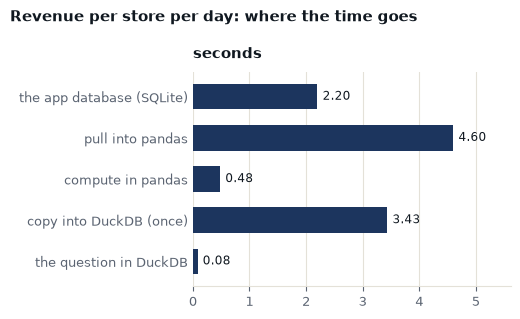

In [6]:
V.bars(pd.DataFrame({"way": list(times), "seconds": list(times.values())}), "way", ["seconds"],
       suptitle="Revenue per store per day: where the time goes", fmt="{:.2f}")

🔍 The same question, the same answer, a fraction of the time, and a file several times smaller. Nothing about the
data changed; only how it is stored and processed. §2 explains both.

| Job | Without it | With DuckDB |
|---|---|---|
| Scan millions of rows, a few columns | a row store reads whole rows | columnar storage, vectorized execution (§2) |
| Run an analytical database | install and operate a server | `pip install duckdb`, runs inside Python (§3) |
| Query a CSV, JSON or Parquet file | load it into a table first | SQL on the file where it is (§4) |
| Combine sources | export, import, glue scripts | attach SQLite or Postgres and join across (§5) |
| Move data between SQL and Python | export to CSV, read back | query DataFrames by name, results as DataFrames (§6) |
| "Why is this slow?" | guess | `EXPLAIN ANALYZE` (§8) |

🎓 Ask before §2: "why is DuckDB's file smaller than SQLite's, with the same rows?" Most rooms get to "columns
compress better" quickly. Keep the OLTP/OLAP point: the app database is right for the app, wrong for this question.

## 2 · The mental model: in-process, columnar, vectorized

```
 ROW STORE (SQLite, PostgreSQL)              COLUMN STORE (DuckDB, Parquet, Snowflake)
 page 1: [1, RUH-04, 08-01, 275.86, …, note] order_id: [1, 2, 3, 4, …]        ← skipped
 page 2: [2, JED-03, 08-01,  33.65, …, note] store_id: [RUH-04, JED-03, …]    ← read
 page 3: [3, RUH-04, 08-01,  12.00, …, note] amount:   [275.86, 33.65, …]     ← read
         sum(amount) reads every page        note:     [...]                  ← skipped
                                             similar values side by side compress well
```

| Idea | What it means | You saw it in §1 |
|---|---|---|
| **In-process** | a library inside your Python process, like SQLite; no server, no network | `pip install`, `duckdb.connect()` |
| **Columnar** | each column stored apart, compressed | reads 3 of 6 columns; a smaller file |
| **Vectorized** | each operator works on batches of ~2,048 values, on all CPU cores | a GROUP BY over 1M rows in a blink |
| **Reads everything** | CSV, JSON, Parquet, Iceberg, SQLite, PostgreSQL, HTTP, S3 | `ATTACH ... (TYPE sqlite)` |

Where it sits among databases you may know:

| | Runs | Stores rows as | Built for |
|---|---|---|---|
| SQLite | in your process | rows | an app's own data: many small reads and writes |
| PostgreSQL, MySQL | a server | rows | many users writing small transactions |
| **DuckDB** | **in your process** | **columns** | **analytics on one machine** |
| Snowflake, BigQuery, Redshift | a managed service | columns | analytics on a cluster, shared by a company |

## 3 · Hello world: a query, a connection, a database file

The smallest DuckDB program:

In [7]:
duckdb.sql("SELECT 42 AS answer, 'مرحبا' AS greeting")

answerINTEGER,greetingVARCHAR
42,مرحبا


Three daily order exports from Qafila's stores, few enough to read. On the third day the export gained a column.

In [8]:
FILES = {
    "orders_2026-09-14.csv": """order_id,store_id,status,amount,delivery_fee
101,RUH-04,delivered,275.86,9.00
102,JED-03,delivered,33.65,9.00
103,RUH-04,cancelled,12.00,0.00
""",
    "orders_2026-09-15.csv": """order_id,store_id,status,amount,delivery_fee
104,RUH-04,delivered,58.10,9.00
105,DMM-01,delivered,19.90,free
106,JED-03,delivered,44.00,9.00
""",
    "orders_2026-09-16.csv": """order_id,store_id,status,amount,delivery_fee,promo_code
107,RUH-04,delivered,8.75,9.00,YAWM96
108,JED-03,delivered,120.00,0.00,
109,DMM-01,delivered,61.25,9.00,YAWM96
110,RUH-04,cancelled,15.50,0.00,
""",
}
for name, text in FILES.items():
    (OUT / name).write_text(text, encoding="utf-8")
U.peek(OUT / "orders_2026-09-14.csv", 4)

order_id,store_id,status,amount,delivery_fee
101,RUH-04,delivered,275.86,9.00
102,JED-03,delivered,33.65,9.00
103,RUH-04,cancelled,12.00,0.00


In [9]:
duckdb.sql(f"SELECT * FROM '{F}/orders_2026-09-14.csv'")

order_idBIGINT,store_idVARCHAR,statusVARCHAR,amountDOUBLE,delivery_feeDOUBLE
101,RUH-04,delivered,275.86,9.0
102,JED-03,delivered,33.65,9.0
103,RUH-04,cancelled,12.0,0.0


🔍 No `CREATE TABLE`, no import: a file path in `FROM` is a table. `duckdb.sql()` runs on a default connection that
lives in memory. In a pipeline you open your own **connection**: in memory, or to a **database file**.

🤔 **Predict** · We create a table in an in-memory connection, close it and connect again. Is the table there?

In [10]:
mem = duckdb.connect()                 # in memory
mem.sql("CREATE TABLE hello AS SELECT 42 AS answer")
mem.close()

mem = duckdb.connect()
try:
    mem.sql("FROM hello")
except duckdb.CatalogException as e:
    print("❌", str(e).splitlines()[0])

❌ Catalog Error: Table with name hello does not exist!


In [11]:
DB = OUT / "qafila_toy.duckdb"
with duckdb.connect(str(DB)) as con:   # a file: created if it doesn't exist
    con.sql("CREATE TABLE hello AS SELECT 42 AS answer")

with duckdb.connect(str(DB)) as con:
    print(con.sql("FROM hello").fetchall(), "| file:", DB.name, f"{U.size_mb(DB):.2f} MB")

[(42,)] | file: qafila_toy.duckdb 0.27 MB


🔍 An in-memory database disappears with its connection: right for exploring and for tests. A `.duckdb` file keeps
every table in one file, like SQLite: the course's warehouse is `warehouse/qafila.duckdb`.

| Code | Gives |
|---|---|
| `duckdb.sql(...)` | the default in-memory connection: quick looks |
| `duckdb.connect()` | a new in-memory database |
| `duckdb.connect("x.duckdb")` | a database file, created if missing |
| `duckdb.connect("x.duckdb", read_only=True)` | the same file, without the right to change it (§5) |
| `with duckdb.connect(...) as con:` | closes the connection at the end of the block |

## 4 · Files where they are: CSV, globs, JSON, Parquet

A CSV has no types: DuckDB **sniffs** them from a sample of the rows. `DESCRIBE` shows what it decided.

🤔 **Predict** · On 15 September one fee says `free`. Which type does `delivery_fee` get in that file?

In [12]:
con = duckdb.connect()                 # in memory, for the rest of the notebook
for day in ["2026-09-14", "2026-09-15"]:
    types = con.sql(f"DESCRIBE FROM '{F}/orders_{day}.csv'").df()
    print(day, dict(zip(types.column_name, types.column_type)))

2026-09-14 {'order_id': 'BIGINT', 'store_id': 'VARCHAR', 'status': 'VARCHAR', 'amount': 'DOUBLE', 'delivery_fee': 'DOUBLE'}
2026-09-15 {'order_id': 'BIGINT', 'store_id': 'VARCHAR', 'status': 'VARCHAR', 'amount': 'DOUBLE', 'delivery_fee': 'VARCHAR'}


🔍 One value that isn't a number and the whole column becomes `VARCHAR`, without an error. Summing it now fails, or
worse, a tool casts it later in a way you didn't choose. **Always look at the types** before trusting a file.

You can take the decision yourself: state the types, and convert the odd values on purpose.

In [13]:
con.sql(f"""
    SELECT order_id, delivery_fee AS as_sent,
           coalesce(TRY_CAST(delivery_fee AS DECIMAL(6, 2)), 0) AS delivery_fee_sar
    FROM read_csv('{F}/orders_2026-09-15.csv', types = {{'delivery_fee': 'VARCHAR'}})""")

order_idBIGINT,as_sentVARCHAR,"delivery_fee_sarDECIMAL(12,2)"
104,9.00,9.00
105,free,0.00
106,9.00,9.00


🔍 `TRY_CAST` gives `NULL` where a cast fails, so the decision ("free" means 0) is in the SQL, visible and testable.
`read_csv` takes many options when sniffing guesses wrong: `types`, `delim`, `header`, `dateformat`,
`all_varchar`. `FROM sniff_csv('file.csv')` shows everything the sniffer decided.

One file per day is the usual shape of an export. A **glob** reads them all at once.

🤔 **Predict** · The third file has a `promo_code` column the others don't. What happens?

In [14]:
con.sql(f"SELECT * FROM read_csv('{F}/orders_*.csv')")

order_idBIGINT,store_idVARCHAR,statusVARCHAR,amountDOUBLE,delivery_feeVARCHAR
101,RUH-04,delivered,275.86,9.00
102,JED-03,delivered,33.65,9.00
103,RUH-04,cancelled,12.0,0.00
104,RUH-04,delivered,58.1,9.00
105,DMM-01,delivered,19.9,free
106,JED-03,delivered,44.0,9.00
107,RUH-04,delivered,8.75,9.00
108,JED-03,delivered,120.0,0.00
109,DMM-01,delivered,61.25,9.00
110,RUH-04,cancelled,15.5,0.00


🔍 No error, ten rows, and no `promo_code`: the columns were taken from the **first** file, and the column only the
third file has was dropped without a word. (Note `delivery_fee` too: one `free` in one file made it text in all.)

`union_by_name = true` takes the columns of **all** files, matched by name, and fills the missing ones with `NULL`.
`filename = true` adds the path each row came from, which is how you trace a bad row back to its file.

In [15]:
con.sql(f"""
    SELECT order_id, store_id, amount, promo_code, parse_filename(filename) AS file
    FROM read_csv('{F}/orders_*.csv', union_by_name = true, filename = true)
    ORDER BY order_id""")

order_idBIGINT,store_idVARCHAR,amountDOUBLE,promo_codeVARCHAR,fileVARCHAR
101,RUH-04,275.86,NULL,orders_2026-09-14.csv
102,JED-03,33.65,NULL,orders_2026-09-14.csv
103,RUH-04,12.0,NULL,orders_2026-09-14.csv
104,RUH-04,58.1,NULL,orders_2026-09-15.csv
105,DMM-01,19.9,NULL,orders_2026-09-15.csv
106,JED-03,44.0,NULL,orders_2026-09-15.csv
107,RUH-04,8.75,YAWM96,orders_2026-09-16.csv
108,JED-03,120.0,NULL,orders_2026-09-16.csv
109,DMM-01,61.25,YAWM96,orders_2026-09-16.csv
110,RUH-04,15.5,NULL,orders_2026-09-16.csv


✏️ **Exercise 1** · One row per file: `file` (the file name), `orders` (count) and `revenue` (sum of `amount` of
delivered orders, use `sum(amount) FILTER (WHERE status = 'delivered')`), ordered by file. Store it as a pandas
DataFrame in `per_file`.
- **Check yourself:** three rows; 16 September's revenue is 190.00.

In [16]:
# Template:
# per_file = con.sql(f"""
#     SELECT parse_filename(filename) AS file, count(*) AS orders,
#            sum(amount) FILTER (WHERE status = 'delivered') AS revenue
#     FROM read_csv('{F}/orders_*.csv', ___ = true, ___ = true)
#     GROUP BY ___
#     ORDER BY file""").df()
per_file = con.sql(f"""
    SELECT parse_filename(filename) AS file, count(*) AS orders,
           sum(amount) FILTER (WHERE status = 'delivered') AS revenue
    FROM read_csv('{F}/orders_*.csv', union_by_name = true, filename = true)
    GROUP BY file
    ORDER BY file""").df()
per_file

,file,orders,revenue
0,orders_2026-09-14.csv,3,309.51
1,orders_2026-09-15.csv,3,122.00
2,orders_2026-09-16.csv,4,190.00


In [17]:
U.check(per_file.file.tolist() == list(FILES), "one row per file, in date order")
U.check(per_file.orders.tolist() == [3, 3, 4], "3, 3 and 4 orders")
U.check(round(float(per_file.revenue.iloc[2]), 2) == 190.00, "16 September: 190.00 SAR delivered")

✅ one row per file, in date order
✅ 3, 3 and 4 orders
✅ 16 September: 190.00 SAR delivered


**JSON** works the same way, and it keeps nesting: an object becomes a `STRUCT` (read it with a dot), a list
becomes a `LIST` (one row per element with `unnest`). The app's API sends orders like this:

In [18]:
(OUT / "order_details.jsonl").write_text(
    '{"order_id": 104, "courier": {"id": "C-17", "vehicle": "bike"}, '
    '"items": [{"sku": "TEA-01", "qty": 2}, {"sku": "DATES-1KG", "qty": 1}]}\n'
    '{"order_id": 105, "courier": {"id": "C-22", "vehicle": "car"}, "items": [{"sku": "MILK-2L", "qty": 3}]}\n',
    encoding="utf-8")
display(con.sql(f"DESCRIBE FROM '{F}/order_details.jsonl'").df()[["column_name", "column_type"]])
con.sql(f"""
    SELECT order_id, courier.vehicle, unnest(items, recursive := true)
    FROM '{F}/order_details.jsonl'""")

,column_name,column_type
0,order_id,BIGINT
1,courier,"STRUCT(id VARCHAR, vehicle VARCHAR)"
2,items,"STRUCT(sku VARCHAR, qty BIGINT)[]"


order_idBIGINT,vehicleVARCHAR,skuVARCHAR,qtyBIGINT
104,bike,TEA-01,2
104,bike,DATES-1KG,1
105,car,MILK-2L,3


🔍 Two orders became three rows, one per item, with the courier's vehicle pulled out of the struct.

**Parquet** is the columnar file format of the course (Lab 1.2). `COPY ... TO` writes any query to a file, and
reading it back needs no options: the types are stored in the file.

In [19]:
con.sql(f"""COPY (SELECT * FROM read_csv('{F}/orders_*.csv', union_by_name = true))
            TO '{F}/orders.parquet' (FORMAT parquet)""")
con.sql(f"DESCRIBE FROM '{F}/orders.parquet'").df()[["column_name", "column_type"]]

,column_name,column_type
0,order_id,BIGINT
1,store_id,VARCHAR
2,status,VARCHAR
3,amount,DOUBLE
4,delivery_fee,VARCHAR
5,promo_code,VARCHAR


| Source | Read with | Notes |
|---|---|---|
| CSV | `FROM 'x.csv'`, `read_csv(...)` | types sniffed: check with `DESCRIBE` |
| JSON, JSON lines | `FROM 'x.json'`, `read_json(...)` | objects → `STRUCT`, lists → `LIST` |
| Parquet | `FROM 'x.parquet'`, `read_parquet(...)` | types stored in the file |
| Many files | `'orders_*.csv'`, `['a.csv', 'b.csv']` | `union_by_name`, `filename` |
| HTTP, S3, GCS, Azure | `FROM 'https://…'`, `'s3://…'` | the `httpfs` extension, loaded on first use |
| Write | `COPY (query) TO 'x.parquet'` | also CSV, JSON; `PARTITION_BY` in Lab 1.2 |

🎓 Lab 1.1 meets the real `free`: week 38's supplier prices are `VARCHAR` because of decimal commas. Let the room
make the link themselves: "where have we seen a number column become text?"

## 5 · Tables, views, other databases, and one writer at a time

Reading a file in place re-reads it on every query. When many queries use the same data, **copy it in** once as a
table. A **view** is the opposite: a saved query, run again each time.

In [20]:
wh = duckdb.connect(str(DB))
wh.sql(f"CREATE TABLE orders AS FROM read_csv('{F}/orders_*.csv', union_by_name = true)")
wh.sql(f"CREATE VIEW orders_live AS FROM read_csv('{F}/orders_*.csv', union_by_name = true)")
wh.sql("SELECT (SELECT count(*) FROM orders) AS in_table, (SELECT count(*) FROM orders_live) AS in_view")

in_tableBIGINT,in_viewBIGINT
10,10


🤔 **Predict** · Thursday's export arrives. How many orders do the table and the view count now?

In [21]:
(OUT / "orders_2026-09-17.csv").write_text(
    "order_id,store_id,status,amount,delivery_fee,promo_code\n111,JED-03,delivered,27.40,9.00,\n", encoding="utf-8")
wh.sql("SELECT (SELECT count(*) FROM orders) AS in_table, (SELECT count(*) FROM orders_live) AS in_view")

in_tableBIGINT,in_viewBIGINT
10,11


🔍 The table is a copy taken when it was created: fast, and it doesn't change under you. The view always shows the
files as they are now. dbt (Day 2) lets you choose per model: `table` or `view`.

**Other databases** can be attached next to yours and joined with it. This is how the setup built the app database,
and how §1 copied it: `ATTACH` with `TYPE sqlite` (PostgreSQL and MySQL work the same way).

In [22]:
wh.sql(f"ATTACH '{APP.as_posix()}' AS app (TYPE sqlite, READ_ONLY)")
display(wh.sql("SELECT database_name, schema_name, table_name FROM duckdb_tables() ORDER BY ALL").df())
wh.sql("""
    SELECT o.store_id, count(*) AS toy_orders, any_value(a.n) AS orders_in_app
    FROM orders o
    JOIN (SELECT store_id, count(*) AS n FROM app.orders GROUP BY ALL) a USING (store_id)
    GROUP BY ALL ORDER BY ALL""")

,database_name,schema_name,table_name
0,app,main,orders
1,qafila_toy,main,hello
2,qafila_toy,main,orders


store_idVARCHAR,toy_ordersBIGINT,orders_in_appBIGINT
DMM-01,2,200000
JED-03,3,200000
RUH-04,5,200000


🔍 One query, two databases, two formats. Lab 1.1 starts exactly like this, on the real app database.

**Break it on purpose.** A `.duckdb` file can be changed by **one process** at a time. Our notebook holds `wh`, a
read-write connection to `qafila_toy.duckdb`. Now a second program (a dbt run, a dashboard, another notebook) tries
to open the same file.

🤔 **Predict** · It only wants to read. Does it get in?

In [23]:
READER = f"import duckdb; print(duckdb.connect(r'{DB}', read_only=True).sql('SELECT count(*) FROM orders').fetchall()[0])"
other = subprocess.run([sys.executable, "-c", READER], capture_output=True, text=True)
print("❌" if other.returncode else "✅", other.stdout.strip() or first_error(other.stderr))

❌ _duckdb.IOException: IO Error: Cannot open file "…/qafila_toy.duckdb": The process cannot access the file because it is being used by another process.


🔍 Refused: while one process may write, no other process may open the file, not even to read. (Inside one process,
many connections and threads are fine.) Close our connection and try again:

In [24]:
wh.close()
other = subprocess.run([sys.executable, "-c", READER], capture_output=True, text=True)
print("❌" if other.returncode else "✅", other.stdout.strip() or first_error(other.stderr))

✅ (10,)


🔍 This is the most common DuckDB error in class: a notebook keeps the warehouse open, and `dbt run` or Dagster
fails with "Could not set lock on file" (Linux, Colab, macOS) or "being used by another process" (Windows). The habits that avoid it:
- open, query, close: `with duckdb.connect(path) as con:` (the dlt walkthrough does this for every query);
- readers use `read_only=True` (several read-only processes can share a file);
- when many people or services must write, use a server or a service (MotherDuck, PostgreSQL, a warehouse), or a
  table format like Iceberg (Day 3).

✏️ **Exercise 2** · In `qafila_toy.duckdb`, create the table `delivered` with the delivered orders of all four
files, then export it to `delivered.parquet` in `OUT`. Open and close the connection in a `with` block.
- **Check yourself:** the Parquet file has 9 rows, and another process can read the database afterwards.

In [25]:
# Template:
# with duckdb.connect(str(DB)) as con_ex:
#     con_ex.sql(f"""CREATE TABLE delivered AS
#                    SELECT * FROM read_csv('{F}/orders_*.csv', union_by_name = true) WHERE ___""")
#     con_ex.sql(f"COPY delivered TO '{F}/___' (FORMAT ___)")
with duckdb.connect(str(DB)) as con_ex:
    con_ex.sql(f"""CREATE TABLE delivered AS
                   SELECT * FROM read_csv('{F}/orders_*.csv', union_by_name = true) WHERE status = 'delivered'""")
    con_ex.sql(f"COPY delivered TO '{F}/delivered.parquet' (FORMAT parquet)")

In [26]:
U.check(con.sql(f"SELECT count(*) FROM '{F}/delivered.parquet'").fetchall()[0][0] == 9, "9 delivered orders in the file")
check_db = subprocess.run([sys.executable, "-c", READER.replace("FROM orders", "FROM delivered")],
                          capture_output=True, text=True)
U.check(check_db.returncode == 0, "the database is free: another process could read it")

✅ 9 delivered orders in the file


✅ the database is free: another process could read it


## 6 · Python in and out: DataFrames, relations, parameters

**In:** a pandas (or Polars, or Arrow) DataFrame in a Python variable can be queried by its **name**, without
copying it anywhere first.

In [27]:
targets = pd.DataFrame({"store_id": ["RUH-04", "JED-03", "DMM-01"], "daily_target": [150.0, 50.0, 35.0]})
con.sql("SELECT * FROM targets WHERE daily_target > 40")

store_idVARCHAR,daily_targetDOUBLE
RUH-04,150.0
JED-03,50.0


**Out:** every result converts to what the next step needs.

| Call | Gives |
|---|---|
| `.df()` | a pandas DataFrame |
| `.pl()` | a Polars DataFrame (Day 2) |
| `.to_arrow_table()` | an Arrow table (PyIceberg, Day 3) |
| `.fetchall()` | a list of Python tuples |
| `.show()` | prints a preview |

For one row, take the first: `.fetchall()[0]`. Older tutorials use `.fetchone()`, which relations lost in DuckDB
2.0; and after `con.execute(...)`, read the whole result (`.fetchall()`, `.df()`): a half-read result keeps the
connection busy until you do.

In [28]:
result = con.sql("SELECT store_id, daily_target FROM targets ORDER BY store_id")
print(type(result.df()).__module__, type(result.pl()).__module__, type(result.to_arrow_table()).__module__)
result.fetchall()

pandas polars.dataframe.frame pyarrow.lib


[('DMM-01', 35.0), ('JED-03', 50.0), ('RUH-04', 150.0)]

What `con.sql(...)` returns is a **relation**: a query that hasn't run yet. It runs when you ask for rows, and
again **every time** you ask.

🤔 **Predict** · We keep a relation that counts the orders in the files, then Friday's file arrives. What does the
same relation say?

In [29]:
order_count = con.sql(f"SELECT count(*) AS orders FROM read_csv('{F}/orders_*.csv', union_by_name = true)")
print("before:", order_count.fetchall())
(OUT / "orders_2026-09-18.csv").write_text(
    "order_id,store_id,status,amount,delivery_fee,promo_code\n112,DMM-01,delivered,33.00,9.00,\n", encoding="utf-8")
print("after: ", order_count.fetchall())

before: [(11,)]
after:  [(12,)]


🔍 A relation is like a view in Python: cheap to keep, re-run (glob included) when used. Call `.df()` (or `.fetchall()`) once when
you want a fixed result. Relations also chain, each step building a bigger query, which is the style Polars uses
(Day 2):

In [30]:
files = con.read_csv(f"{F}/orders_*.csv", union_by_name=True)
files.filter("status = 'delivered'").aggregate("store_id, round(sum(amount), 2) AS revenue").order("revenue DESC")

store_idVARCHAR,revenueDOUBLE
RUH-04,342.71
JED-03,225.05
DMM-01,114.15


**Parameters.** When a value comes from Python (a date, a store picked in a dashboard), pass it as a parameter, not
pasted into the SQL string: no quoting bugs, and no SQL injection.

In [31]:
store = "JED-03"
con.execute(f"SELECT order_id, amount FROM read_csv('{F}/orders_*.csv', union_by_name = true) WHERE store_id = ?",
            [store]).df()

,order_id,amount
0,102,33.65
1,106,44.00
2,108,120.00
3,111,27.40


✏️ **Exercise 3** · Compare each store's delivered revenue with its target. Join the files to the `targets`
DataFrame and build `vs_target` (pandas) with `store_id`, `revenue`, `daily_target`, `days` (distinct files the
store sold in) and `met` (`revenue >= daily_target * days`), ordered by `store_id`.
- **Check yourself:** three stores; only `RUH-04` misses its target.

In [32]:
# Template:
# vs_target = con.sql(f"""
#     SELECT o.store_id, sum(o.amount) AS revenue, any_value(t.daily_target) AS daily_target,
#            count(DISTINCT o.filename) AS days,
#            sum(o.amount) >= any_value(t.daily_target) * count(DISTINCT o.filename) AS met
#     FROM read_csv('{F}/orders_*.csv', union_by_name = true, filename = true) o
#     JOIN ___ t USING (store_id)
#     WHERE o.status = '___'
#     GROUP BY ___
#     ORDER BY o.store_id""").___()
vs_target = con.sql(f"""
    SELECT o.store_id, sum(o.amount) AS revenue, any_value(t.daily_target) AS daily_target,
           count(DISTINCT o.filename) AS days,
           sum(o.amount) >= any_value(t.daily_target) * count(DISTINCT o.filename) AS met
    FROM read_csv('{F}/orders_*.csv', union_by_name = true, filename = true) o
    JOIN targets t USING (store_id)
    WHERE o.status = 'delivered'
    GROUP BY o.store_id
    ORDER BY o.store_id""").df()
vs_target

,store_id,revenue,daily_target,days,met
0,DMM-01,114.15,35.0,3,True
1,JED-03,225.05,50.0,4,True
2,RUH-04,342.71,150.0,3,False


In [33]:
U.check(vs_target.store_id.tolist() == ["DMM-01", "JED-03", "RUH-04"], "three stores, in order")
U.check(vs_target.loc[~vs_target.met, "store_id"].tolist() == ["RUH-04"], "only RUH-04 misses its target")

✅ three stores, in order
✅ only RUH-04 misses its target


## 7 · Friendly SQL ➕

DuckDB's SQL is PostgreSQL-like, plus shortcuts that make exploring faster. The labs use them, so here they are once.

In [34]:
con.sql(f"CREATE OR REPLACE TABLE o AS FROM read_csv('{F}/orders_*.csv', union_by_name = true)")
con.sql("""
    FROM o                                         -- FROM first; SELECT * is implied
    SELECT * EXCLUDE (delivery_fee, promo_code)    -- every column but these
             REPLACE (round(amount) AS amount)     -- ...with this one changed
    WHERE status = 'delivered'
    LIMIT 3""")

order_idBIGINT,store_idVARCHAR,statusVARCHAR,amountDOUBLE
101,RUH-04,delivered,276.0
102,JED-03,delivered,34.0
104,RUH-04,delivered,58.0


In [35]:
con.sql("""
    SELECT store_id, status, count(*) AS orders, max_by(order_id, amount) AS biggest_order
    FROM o
    GROUP BY ALL                                   -- group by every column that isn't aggregated
    ORDER BY ALL                                   -- order by every column, left to right""")

store_idVARCHAR,statusVARCHAR,ordersBIGINT,biggest_orderBIGINT
DMM-01,delivered,3,109
JED-03,delivered,4,108
RUH-04,cancelled,2,110
RUH-04,delivered,3,101


In [36]:
con.sql("PIVOT o ON status USING round(sum(amount), 2) GROUP BY store_id ORDER BY store_id")

store_idVARCHAR,cancelledDOUBLE,deliveredDOUBLE
DMM-01,NULL,114.15
JED-03,NULL,225.05
RUH-04,27.5,342.71


In [37]:
con.sql("SUMMARIZE o").df()[["column_name", "column_type", "min", "max", "approx_unique", "null_percentage"]]

,column_name,column_type,min,max,approx_unique,null_percentage
0,order_id,BIGINT,101,112,12,0.00
1,store_id,VARCHAR,DMM-01,RUH-04,3,0.00
2,status,VARCHAR,cancelled,delivered,2,0.00
3,amount,DOUBLE,8.75,275.86,12,0.00
4,delivery_fee,VARCHAR,0.00,free,3,0.00
5,promo_code,VARCHAR,YAWM96,YAWM96,1,83.33


| Shortcut | Does |
|---|---|
| `FROM t` / `FROM t SELECT ...` | `SELECT * FROM t` / FROM written first |
| `SELECT * EXCLUDE (a)`, `* REPLACE (expr AS a)` | all columns but some / with some changed |
| `GROUP BY ALL`, `ORDER BY ALL` | no need to repeat the columns |
| `COLUMNS('regex')` | the same expression on every matching column: `SELECT max(COLUMNS('amount|fee'))` |
| `max_by(x, y)`, `arg_min`, `FILTER (WHERE ...)` | the `x` of the largest `y`; conditional aggregates |
| `PIVOT`, `UNPIVOT` | rows ↔ columns |
| `DESCRIBE`, `SUMMARIZE` | the types / a profile of every column (Lab 1.1) |
| `QUALIFY` | filter on a window function (`00_sql_windows`, Lab 1.4) |

## 8 · Read the plan: EXPLAIN and EXPLAIN ANALYZE ➕

DuckDB turns your SQL into a **plan**: a tree of operators, read **from the bottom up**: scan, filter, aggregate,
project. `EXPLAIN` shows the plan without running it. We write the big orders table to Parquet and ask §1's question
of the file.

In [38]:
with duckdb.connect(f"{F}/analytics.duckdb", read_only=True) as src:
    src.sql(f"COPY orders TO '{F}/big_orders.parquet' (FORMAT parquet)")
BIG = f"'{Path(os.path.relpath(OUT / 'big_orders.parquet')).as_posix()}'"   # relative: a shorter plan
print(con.sql(f"""EXPLAIN SELECT store_id, sum(amount) FROM {BIG}
                  WHERE status = 'delivered' GROUP BY ALL""").fetchall()[0][1])

╭─ Hash Group By ───────────────╮
│ Groups: #0                    │
│ Aggregates: sum(#1)           │
│ ~126,424 rows                 │
╰───────────────┬───────────────╯
╭─ Projection ──┴───────────────╮
│ Projections: store_id, amount │
│ ~200,000 rows                 │
╰───────────────┬───────────────╯
╭─ Parquet Scan ┴───────────────╮
│ Function: PARQUET_SCAN        │
│ Projections: store_id, amount │
│ Filters: status = 'delivered' │
│ ~200,000 rows                 │
╰───────────────────────────────╯



🔍 Start at the bottom box, the **Parquet Scan**. It already knows two things from the query:
- **Projections**: only `store_id` and `amount` are read. The other columns are never touched (columnar).
- **Filters**: `status='delivered'` is applied inside the scan, while reading (a **pushed-down** filter).

Above it, a **Hash Group By** sums per store. A **Projection** only passes columns between operators. The `~` rows
are estimates: DuckDB guesses how many rows pass the filter before it reads anything. (DuckDB 1.x draws the same
tree with square boxes and names like `PARQUET_SCAN`, `HASH_GROUP_BY`.)

`EXPLAIN ANALYZE` **runs** the query: a **Summary** box on top (total time, data read), then each operator with its
real rows and time. The cell prints the total time and the bottom box.

In [39]:
profile = con.sql(f"""EXPLAIN ANALYZE SELECT store_id, sum(amount) FROM {BIG}
                      WHERE status = 'delivered' GROUP BY ALL""").fetchall()[0][1]
print(re.search(r"Total Time: \S+", profile).group())
print(profile[profile.rindex("╭─"):])                     # the last box: the scan

Total Time: 0.0363s
╭─ Table Scan ────────┚┖────────────────────╮
│ Function: PARQUET_SCAN                    │
│ Projections: store_id, amount             │
│ Filters: status = 'delivered'             │
│ Total Files Read: 1                       │
│ Filename(s):                              │
│ artifacts/tools_duckdb/big_orders.parquet │
│ Row Groups Scanned: 9 / 9                 │
│ 941,176 rows                      140.0ms │
╰───────────────────────────────────────────╯



🔍 Now the rows are real: the scan produced only the delivered orders (the cancelled ones never left it), and each
operator shows its time. When a query is slow, this tells
you **where**: a scan reading too much (Lab 1.2's row groups and partitions), a join exploding, a sort spilling to
disk.

🤔 **Predict** · DuckDB uses all CPU cores by default. How much slower is the same question on **one** thread?

In [40]:
question = f"SELECT store_id, sum(amount) FROM {BIG} WHERE status = 'delivered' GROUP BY ALL"
cores = con.sql("SELECT current_setting('threads')").fetchall()[0][0]
all_cores = U.best_of(lambda: con.sql(question).fetchall())
con.sql("SET threads = 1")
one_core = U.best_of(lambda: con.sql(question).fetchall())
con.sql(f"SET threads = {cores}")
print(f"{cores} threads: {all_cores * 1000:.0f} ms | 1 thread: {one_core * 1000:.0f} ms | {one_core / all_cores:.1f}x")

8 threads: 33 ms | 1 thread: 94 ms | 2.8x


🔍 Vectorized operators split the work into batches that every core can take. On a laptop that is the parallelism
you get for free; beyond one machine you need a cluster (Spark, Day 3). Two more settings worth knowing:
`SET memory_limit = '2GB'` (DuckDB spills to disk past it, so data larger than memory still works) and
`SET preserve_insertion_order = false` (less memory for big exports).

🎓 On Colab's 2 cores the speed-up is small; say so before running it. Don't go deeper into plans here: Lab 1.2
counts the row groups the scan skips, and Lab 2.1 compares DuckDB's plan with Polars'.

## 9 · Back to the map

DuckDB **stores** tables in one file, **transforms** them with SQL, and **serves** the answers to Python, BI tools
and the other tools of the course.

In [41]:
V.platform_map(tool="duckdb")

| | |
|---|---|
| **It does** | SQL analytics on one machine, fast · files in place (CSV, JSON, Parquet, Iceberg) · attach SQLite / PostgreSQL · DataFrames in and out · larger-than-memory work by spilling to disk |
| **It doesn't** | serve an app (many small writes from many users: that's PostgreSQL) · let several processes write one file · scale past one machine (Spark, Day 3) · ingest, schedule or test by itself (dlt, Dagster, dbt) |
| **In this course** | the dlt destination (Lab 1.3) · the engine under dbt (`dbt-duckdb`, Lab 2.3) · the warehouse `warehouse/qafila.duckdb` · a reader of Iceberg tables (Lab 3.1) |
| **Managed equivalents** | Snowflake, BigQuery, Redshift, Databricks SQL: the same columnar SQL as a service; MotherDuck: DuckDB as a service |
| **Neighbours** | Polars (the same engine ideas behind a DataFrame API, Day 2) · chDB / ClickHouse · DataFusion · SQLite (in-process, but rows) |

**Cheat sheet**

| Code | Does |
|---|---|
| `duckdb.connect()` / `duckdb.connect("x.duckdb", read_only=True)` | in memory / a database file |
| `con.sql("...")` | a relation: runs when you ask for rows |
| `.df()`, `.pl()`, `.fetchall()` | results as pandas, Polars, tuples |
| `FROM 'x.csv'`, `read_csv(..., types = {...})` | a file as a table; take the types into your own hands |
| `read_csv('*.csv', union_by_name = true, filename = true)` | many files, matched by column name, traced to their file |
| `CREATE TABLE t AS ...`, `CREATE VIEW v AS ...` | a copy / a saved query |
| `ATTACH 'app.sqlite' AS app (TYPE sqlite, READ_ONLY)` | another database, joinable |
| `COPY (query) TO 'x.parquet' (FORMAT parquet)` | write a file |
| `con.execute("... WHERE id = ?", [value])` | a parameter from Python |
| `DESCRIBE`, `SUMMARIZE`, `EXPLAIN`, `EXPLAIN ANALYZE` | types, profile, plan, plan with timings |

## Checkpoint

1. The app database and DuckDB gave the same answer. Why was one so much faster, and why was its file smaller?
2. Pulling the table into pandas: what was slow, the computing or the moving?
3. A column you expect to be numeric comes out as `VARCHAR`. What do you do, and what do you not do?
4. Table or view for daily files that keep arriving: when is each right?
5. `dbt run` fails with "could not set lock on file". What is holding it, and what are two ways to avoid it?

Next: [Lab 1.1 · Platform tour with DuckDB](../D1_1_platform_tour.ipynb). Docs:
[Python API](https://duckdb.org/docs/stable/clients/python/overview) ·
[CSV import](https://duckdb.org/docs/stable/data/csv/overview) ·
[friendly SQL](https://duckdb.org/docs/stable/sql/dialect/friendly_sql) ·
[concurrency](https://duckdb.org/docs/stable/connect/concurrency) ·
[EXPLAIN](https://duckdb.org/docs/stable/guides/meta/explain).

## 🖼️ Visual summary

**The toy database you built:** the tables and the view in `qafila_toy.duckdb`.

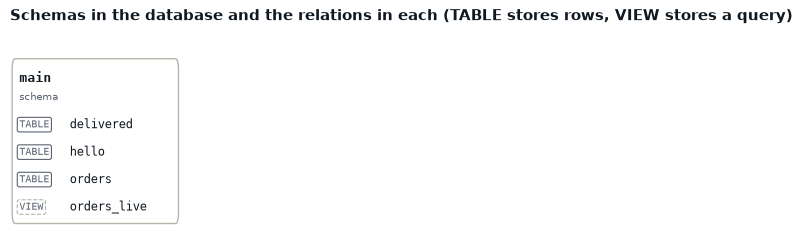

In [42]:
with duckdb.connect(str(DB), read_only=True) as db:
    V.database_map(db.sql("SELECT table_schema, table_name, table_type FROM information_schema.tables").df())